In [81]:
%pip install -q pandas numpy yfinance matplotlib statsmodels


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [82]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import statsmodels.api as sm

print("Libraries imported successfully!")

Libraries imported successfully!


In [83]:
# Load commodity index and equity data

start = "2006-01-01"
end = "2026-10-01"

# Download SPY prices
spy = yf.download(
    "SPY",
    start=start,
    end=end,
    auto_adjust=True,
    progress=False
)["Close"].squeeze()

spy.name = "SPY"

# Load the two commodity index CSV files
file1 = pd.read_csv("GSCI_2006.csv")
file2 = pd.read_csv("GSCI_2025.csv")


gsci = pd.concat([file1, file2], ignore_index=True)

# Clean and organize commodity prices
gsci["Date"] = pd.to_datetime(gsci["Date"])

gsci["Price"] = pd.to_numeric(
    gsci["Price"].astype(str).str.replace(",", "", regex=False)
)

gsci = gsci.drop_duplicates(subset="Date")
gsci = gsci.sort_values("Date")
gsci = gsci.set_index("Date")["Price"]
gsci.name = "GSCI"

# Combine both assets
prices = pd.concat([spy, gsci], axis=1, sort=True)

print(prices.head())
print("\nGSCI period:", gsci.index.min(), "to", gsci.index.max())

                  SPY       GSCI
Date                            
2006-01-03  86.785400  6729.9888
2006-01-04  87.196358  6736.5151
2006-01-05  87.251160  6638.1802
2006-01-06  87.977280  6728.1802
2006-01-09  88.203300  6648.5171

GSCI period: 2006-01-03 00:00:00 to 2026-09-30 00:00:00


In [84]:
# Convert daily prices into monthly returns

monthly_prices = prices.resample("ME").last()

monthly_returns = monthly_prices.pct_change(fill_method=None)

monthly_returns = monthly_returns.dropna()

print(monthly_returns.head())
print("\nNumber of months:", len(monthly_returns))
print("Period:", monthly_returns.index.min(), "to",
      monthly_returns.index.max())

                 SPY      GSCI
Date                          
2006-02-28  0.005726 -0.101044
2006-03-31  0.016504  0.051304
2006-04-30  0.012632  0.063334
2006-05-31 -0.030121 -0.007696
2006-06-30  0.002609  0.011624

Number of months: 248
Period: 2006-02-28 00:00:00 to 2026-09-30 00:00:00


In [85]:
# Download US Consumer Price Index (CPI) from FRED

cpi_url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=CPIAUCSL"

cpi = pd.read_csv(
    cpi_url,
    index_col=0,
    parse_dates=True
)

cpi.index = cpi.index.to_period("M").to_timestamp("M")

print(cpi.head())
print("\nNumber of CPI observations:", len(cpi))

                  CPIAUCSL
observation_date          
1947-01-31           21.48
1947-02-28           21.62
1947-03-31           22.00
1947-04-30           22.00
1947-05-31           21.95

Number of CPI observations: 957


In [86]:
# Calculate monthly and annual inflation rates

cpi["Monthly_Inflation"] = cpi["CPIAUCSL"].pct_change(fill_method=None)

cpi["Annual_Inflation"] = cpi["CPIAUCSL"].pct_change(
    periods=12,
    fill_method=None
)

print(cpi.loc["2021-01":"2022-12"].tail(10))

                  CPIAUCSL  Monthly_Inflation  Annual_Inflation
observation_date                                               
2022-03-31         287.674           0.011156          0.085722
2022-04-30         288.561           0.003083          0.082318
2022-05-31         291.298           0.009485          0.085382
2022-06-30         294.957           0.012561          0.089794
2022-07-31         294.913          -0.000149          0.084626
2022-08-31         295.097           0.000624          0.082226
2022-09-30         296.349           0.004243          0.081921
2022-10-31         298.007           0.005595          0.077588
2022-11-30         298.786           0.002614          0.071229
2022-12-31         298.832           0.000154          0.064046


In [87]:
# Combine asset returns and inflation data

data = monthly_returns.join(
    cpi[["Monthly_Inflation", "Annual_Inflation"]],
    how="inner"
)

print(data.head())
print("\nNumber of observations:", len(data))
print("\nMissing values:")
print(data.isna().sum())

                 SPY      GSCI  Monthly_Inflation  Annual_Inflation
Date                                                               
2006-02-28  0.005726 -0.101044           0.000502          0.036383
2006-03-31  0.016504  0.051304           0.001505          0.034179
2006-04-30  0.012632  0.063334           0.005008          0.036138
2006-05-31 -0.030121 -0.007696           0.002990          0.039773
2006-06-30  0.002609  0.011624           0.002484          0.041817

Number of observations: 248

Missing values:
SPY                  0
GSCI                 0
Monthly_Inflation    2
Annual_Inflation     1
dtype: int64


In [88]:
# Check and remove missing observations

print("Rows with missing values:")
print(data[data.isna().any(axis=1)])

data = data.dropna()

print("\nFinal number of observations:", len(data))
print("Period:", data.index.min(), "to", data.index.max())

Rows with missing values:
                 SPY      GSCI  Monthly_Inflation  Annual_Inflation
Date                                                               
2025-10-31  0.023837  0.013500                NaN               NaN
2025-11-30  0.001950 -0.000749                NaN          0.026964

Final number of observations: 246
Period: 2006-02-28 00:00:00 to 2026-09-30 00:00:00


In [89]:
# Calculate real returns using the lecture formula

data["GSCI_Real"] = data["GSCI"] - data["Monthly_Inflation"]

data["SPY_Real"] = data["SPY"] - data["Monthly_Inflation"]

print(data[["GSCI_Real", "SPY_Real"]].head())

            GSCI_Real  SPY_Real
Date                           
2006-02-28  -0.101546  0.005224
2006-03-31   0.049800  0.014999
2006-04-30   0.058327  0.007624
2006-05-31  -0.010686 -0.033111
2006-06-30   0.009141  0.000125


In [90]:
# Classify months into inflation regimes

threshold = data["Annual_Inflation"].quantile(0.80)

data["Inflation_Regime"] = np.where(
    data["Annual_Inflation"] > threshold,
    "High Inflation",
    "Normal Inflation"
)

print("Inflation threshold:", round(threshold * 100, 2), "%")
print("\nMonths in each regime:")
print(data["Inflation_Regime"].value_counts())

Inflation threshold: 3.64 %

Months in each regime:
Inflation_Regime
Normal Inflation    197
High Inflation       49
Name: count, dtype: int64


In [91]:
# Calculate mean real returns and volatility by inflation regime

performance = data.groupby("Inflation_Regime")[
    ["GSCI_Real", "SPY_Real"]
].agg(["mean", "std", "count"])

print(performance.round(4))

                 GSCI_Real               SPY_Real              
                      mean     std count     mean     std count
Inflation_Regime                                               
High Inflation     -0.0035  0.0752    49  -0.0113  0.0545    49
Normal Inflation    0.0004  0.0630   197   0.0123  0.0391   197


In [92]:
# Estimate inflation beta within each regime

results = []

for regime in ["High Inflation", "Normal Inflation"]:
    subset = data[data["Inflation_Regime"] == regime]

    for asset in ["GSCI", "SPY"]:
        X = sm.add_constant(subset["Monthly_Inflation"])
        y = subset[asset]

        model = sm.OLS(y, X).fit()

        results.append({
            "Regime": regime,
            "Asset": asset,
            "Inflation_Beta": model.params["Monthly_Inflation"],
            "Standard_Error": model.bse["Monthly_Inflation"],
            "P_Value": model.pvalues["Monthly_Inflation"]
        })

beta_results = pd.DataFrame(results)

print(beta_results.round(4))

             Regime Asset  Inflation_Beta  Standard_Error  P_Value
0    High Inflation  GSCI         10.4342          2.7400   0.0004
1    High Inflation   SPY          3.8912          2.1829   0.0811
2  Normal Inflation  GSCI         11.3836          1.4811   0.0000
3  Normal Inflation   SPY          1.6619          1.0276   0.1074


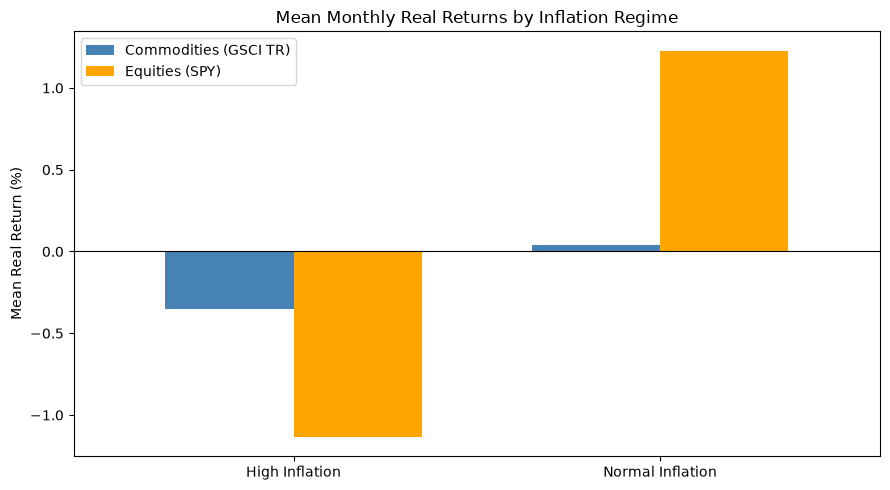

In [93]:
# Compare mean real returns across inflation regimes

mean_returns = data.groupby("Inflation_Regime")[
    ["GSCI_Real", "SPY_Real"]
].mean() * 100

mean_returns = mean_returns.reindex([
    "High Inflation", "Normal Inflation"
])

ax = mean_returns.plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "orange"],
    width=0.7
)

ax.set_title("Mean Monthly Real Returns by Inflation Regime")
ax.set_ylabel("Mean Real Return (%)")
ax.set_xlabel("")
ax.legend(["Commodities (GSCI TR)", "Equities (SPY)"])
ax.axhline(0, color="black", linewidth=0.8)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

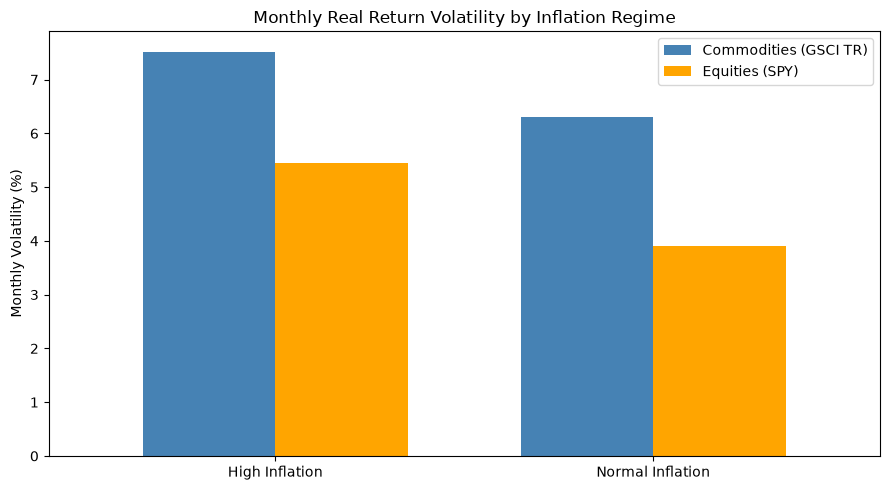

In [94]:
# Compare monthly volatility across inflation regimes

volatility = data.groupby("Inflation_Regime")[
    ["GSCI_Real", "SPY_Real"]
].std() * 100

volatility = volatility.reindex([
    "High Inflation", "Normal Inflation"
])

ax = volatility.plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "orange"],
    width=0.7
)

ax.set_title("Monthly Real Return Volatility by Inflation Regime")
ax.set_ylabel("Monthly Volatility (%)")
ax.set_xlabel("")
ax.legend(["Commodities (GSCI TR)", "Equities (SPY)"])

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [95]:
# Examine high-inflation observations by year

high_inflation = data[
    data["Inflation_Regime"] == "High Inflation"
]

high_inflation_years = high_inflation.groupby(
    high_inflation.index.year
).size()

print("High-inflation months by year:")
print(high_inflation_years)

print("\nTotal high-inflation months:", len(high_inflation))
print("Number of years represented:", len(high_inflation_years))

High-inflation months by year:
Date
2006     4
2007     2
2008    10
2011     2
2021     9
2022    12
2023     7
2026     3
dtype: int64

Total high-inflation months: 49
Number of years represented: 8


In [96]:
# Check CPI data around the missing months

print(cpi.loc["2025-08":"2026-01", [
    "CPIAUCSL",
    "Monthly_Inflation",
    "Annual_Inflation"
]])

                  CPIAUCSL  Monthly_Inflation  Annual_Inflation
observation_date                                               
2025-08-31         323.291           0.003483          0.029386
2025-09-30         324.245           0.002951          0.030226
2025-10-31             NaN                NaN               NaN
2025-11-30         325.063                NaN          0.026964
2025-12-31         326.031           0.002978          0.026533
2026-01-31         326.588           0.001708          0.023912


In [97]:
# Final dataset quality check

print("Total observations:", len(data))
print("Start date:", data.index.min().date())
print("End date:", data.index.max().date())

print("\nMissing values:")
print(data.isna().sum())

print("\nInflation regimes:")
print(data["Inflation_Regime"].value_counts())

Total observations: 246
Start date: 2006-02-28
End date: 2026-09-30

Missing values:
SPY                  0
GSCI                 0
Monthly_Inflation    0
Annual_Inflation     0
GSCI_Real            0
SPY_Real             0
Inflation_Regime     0
dtype: int64

Inflation regimes:
Inflation_Regime
Normal Inflation    197
High Inflation       49
Name: count, dtype: int64


In [98]:
# Create final summary table

summary = []

for regime in ["High Inflation", "Normal Inflation"]:
    for asset in ["GSCI", "SPY"]:
        subset = data[data["Inflation_Regime"] == regime]

        beta_row = beta_results[
            (beta_results["Regime"] == regime) &
            (beta_results["Asset"] == asset)
        ].iloc[0]

        summary.append({
            "Regime": regime,
            "Asset": asset,
            "Mean Real Return (%)": subset[asset + "_Real"].mean() * 100,
            "Volatility (%)": subset[asset + "_Real"].std() * 100,
            "Inflation Beta": beta_row["Inflation_Beta"],
            "Beta SE": beta_row["Standard_Error"],
            "N": len(subset)
        })

summary_df = pd.DataFrame(summary)

print(summary_df.round(2).to_string(index=False))

          Regime Asset  Mean Real Return (%)  Volatility (%)  Inflation Beta  Beta SE   N
  High Inflation  GSCI                 -0.35            7.52           10.43     2.74  49
  High Inflation   SPY                 -1.13            5.45            3.89     2.18  49
Normal Inflation  GSCI                  0.04            6.30           11.38     1.48 197
Normal Inflation   SPY                  1.23            3.91            1.66     1.03 197


In [99]:
# Robustness check: exclude 2021–2023

robust_data = data[
    ~data.index.year.isin([2021, 2022, 2023])
]

robust_high = robust_data[
    robust_data["Inflation_Regime"] == "High Inflation"
]

print("High-inflation months remaining:", len(robust_high))

print("\nMean monthly real returns (%):")
print(
    (robust_high[["GSCI_Real", "SPY_Real"]].mean() * 100).round(2)
)

High-inflation months remaining: 21

Mean monthly real returns (%):
GSCI_Real   -2.11
SPY_Real    -2.22
dtype: float64
